In [1]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import polars as pl
import time
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import OrdinalEncoder
import os
import gc
import matplotlib.pyplot as plt
import warnings
import sys
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset
import random

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
from merlin.loader.torch import Loader
from merlin.io import Dataset as Dataset_merlin

os.environ["CUDA_VISIBLE_DEVICES"] = "0"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = torch.device("cpu")
print(device)

sys.path.append("../src/otto_recommender")
import utils

warnings.filterwarnings("ignore")
tqdm.pandas()

pd.set_option("max_rows", 500)

%matplotlib inline

cuda


In [2]:
def seed_everything(seed):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False  # set True to be faster
    # torch.use_deterministic_algorithms(True)
    print(f"Setting all seeds to be {seed} to reproduce...")


seed_everything(42)

Setting all seeds to be 42 to reproduce...


In [3]:
class Config:
    col_user = "user"
    col_aid = "aid"
    col_type = "type"
    col_n_session = "n_session"
    col_n_day = "n_day"
    col_n_week = "n_week"
    col_dayofweek = "dayofweek"
    col_hour = "hour"
    col_ts = "ts"
    col_num_action = "num_action"
    col_train_seq = "train_seq"
    col_target = "target"
    col_type_group = "type_group"
    path_data = "../data/02_intermediate/"
    batch_size_train = 512
    batch_size_infer = 512
    n_epochs = 10
    max_len = 10
    model_name = "def_tune_"
    hidden_dim = 128
    embedding_dim = 100
    init_lr = 0.0005
    cur_model_path = "def_tune__epoch11_larger_lr_and_bs.pth"
    cur_model_output_path = "../data/07_model_output/"
    new_split = "_new_split"


config = Config()

In [4]:
%%time

X_train, X_val, X_val_seq, ordinal_encoder = utils.get_train_val_dfs(config, do_ordinal_encoder_transform=False, new_split=True)
# X_train, X_val, X_val_seq, ordinal_encoder = utils.dfs_interactions_to_list(
#     config, 
#     X_train, 
#     X_val, 
#     X_val_seq, 
#     ordinal_encoder, 
#     return_only_val=True, 
#     truncate_val=True
# )
pad = ordinal_encoder.unknown_value

CPU times: user 16min 6s, sys: 2min 42s, total: 18min 48s
Wall time: 1min 51s


In [5]:
del X_train, X_val_seq
gc.collect()

190

In [6]:
X_val.shape

(1855354, 6)

In [7]:
# X_val = X_val.filter(pl.col("type") != "clicks")
X_val = X_val.filter(pl.col("type") == "orders")

In [8]:
X_val.shape

(30796, 6)

In [9]:
X_val.filter(pl.col("user") == 12899780)

user,aid,ts,type,n_session,num_action
i64,i64,i64,str,i32,i32


In [10]:
mod = "val"

In [11]:
%%time

dict_models_preds = dict()

cols_to_drop = ['index']

cols_to_rename = dict()
cols_to_rename[config.col_user] = 'session'
cols_to_rename['item_id'] = 'preds'

cols_to_add_model_name = ['preds']

model_names = [
    'rnn', 'weak_nns', #'popular_at_day',  #'rnn_triplet', 'dssm_ep1',
    'cooc_smart', 'bm25', 'tfidf', 'cosine', 'last_items']

for model_name in model_names:
    dict_models_preds[model_name] = pl.read_parquet(config.cur_model_output_path + f'cur_{model_name}_df_{mod}_preds_100{config.new_split}.parquet')
    for col in cols_to_drop:
        if col in dict_models_preds[model_name]:
            dict_models_preds[model_name] = dict_models_preds[model_name].drop(col)
    for col in cols_to_rename:
        if col in dict_models_preds[model_name]:
            dict_models_preds[model_name] = dict_models_preds[model_name].rename({col: cols_to_rename[col]})
    for col in cols_to_add_model_name:
        if col in dict_models_preds[model_name]:
            dict_models_preds[model_name] = dict_models_preds[model_name].rename({col: model_name + '_' + col})
    if 'rnn' in model_name:
        dict_models_preds[model_name] = dict_models_preds[model_name].rename({'preds_scores': f'{model_name}_score'})
        dict_models_preds[model_name] = dict_models_preds[model_name].with_column(
            pl.col(f'{model_name}_score')
                .rank(method="ordinal", reverse=True)
                .over(["session"])
                .alias(f'{model_name}_rank')
        )
        # if model_name in ['rnn_triplet']:
        #     dict_models_preds[model_name] = dict_models_preds[model_name].filter(pl.col(f'{model_name}_rank') <= 50)
    elif model_name in ['cooc_smart']:
        for col in ['cooc_triplet_score_0', 'cooc_triplet_rank_0', 'cooc_score_0', 'cooc_rank_0']:
            if col in dict_models_preds[model_name]:
                dict_models_preds[model_name] = dict_models_preds[model_name].rename({col: col[:-2]})
    for col in dict_models_preds[model_name].columns:
        if 'preds' in col:
            dict_models_preds[model_name] = dict_models_preds[model_name].rename({col: 'item_id'})

for model_name in model_names:
    dict_models_preds[model_name] = dict_models_preds[model_name].with_columns(
    [
        pl.col("item_id").cast(pl.Int32, strict=False).alias("item_id"),
        pl.col("session").cast(pl.Int32, strict=False).alias("session"),
    ]
)

CPU times: user 2min 43s, sys: 27.5 s, total: 3min 11s
Wall time: 50.8 s


In [12]:
dict_models_preds["bm25"].head()

item_id,bm25_score,bm25_rank,session
i32,f64,i64,i32
173749,8810.532819,1,12993152
1490218,5558.81785,2,12993152
59736,2775.519105,3,12993152
1126998,2095.861986,4,12993152
443743,1927.304366,5,12993152


In [13]:
dict_models_preds["last_items"].head()

item_id,last_items_rank,session
i32,i64,i32
840568,1,14563392
716151,1,14511424
1749875,1,13711552
1230981,2,13711552
339663,3,13711552


In [14]:
dict_models_preds["weak_nns"].head()

session,item_id,weak_nns_score,weak_nns_rank
i32,i32,i32,u32
14571581,1100210,2,1
14571581,1265877,1,2
14571581,258767,1,3
14571581,280467,1,4
14571581,195381,1,5


In [15]:
model_names

['rnn', 'weak_nns', 'cooc_smart', 'bm25', 'tfidf', 'cosine', 'last_items']

In [16]:
%%time

df_merged = dict_models_preds[model_names[0]]
for i in tqdm(range(1, len(model_names))):
    model_name_cur = model_names[i]
    df_merged = utils.polars_outer_merge(df_merged, dict_models_preds[model_name_cur])
    df_merged = utils.cast_to_float32(df_merged)

    del dict_models_preds[model_name_cur]
    gc.collect()

    if i == 1:
        del dict_models_preds[model_names[0]]
        gc.collect()

  0%|          | 0/6 [00:00<?, ?it/s]

CPU times: user 41min 30s, sys: 12min 20s, total: 53min 50s
Wall time: 22min 19s


In [17]:
%%time

X_val_lists = X_val.groupby([config.col_user]).agg(
    [
        pl.col(config.col_aid).list().alias(config.col_train_seq),
    ]
)

CPU times: user 43.7 ms, sys: 41.2 ms, total: 84.9 ms
Wall time: 31.5 ms


In [18]:
%%time

df_targets = utils.create_targets_df(list(X_val_lists.to_pandas()[config.col_train_seq]))

CPU times: user 58.5 ms, sys: 0 ns, total: 58.5 ms
Wall time: 57.8 ms


In [19]:
%%time

df_users = pl.from_pandas(X_val_lists.to_pandas()[[config.col_user]].reset_index())
df_users = df_users.join(df_targets, on='index', how='inner')
df_users = df_users.drop('index')
df_users = df_users.rename({config.col_user: 'session'})

CPU times: user 135 ms, sys: 85.5 ms, total: 220 ms
Wall time: 60.8 ms


In [20]:
del df_targets, dict_models_preds, X_val_lists, X_val
gc.collect()

370

In [21]:
df_users = df_users.with_columns(
    [
        pl.col("target").cast(pl.Float32, strict=False).alias("target"),
        pl.col("item_id").cast(pl.Int32, strict=False).alias("item_id"),
        pl.col("session").cast(pl.Int32, strict=False).alias("session"),
    ]
)

In [22]:
df_merged = df_merged.with_columns(
    [
        pl.col("item_id").cast(pl.Int32, strict=False).alias("item_id"),
        pl.col("session").cast(pl.Int32, strict=False).alias("session"),
    ]
)

In [23]:
%%time

df_merged = utils.polars_outer_merge(df_merged, df_users)

CPU times: user 1min 14s, sys: 1min 28s, total: 2min 42s
Wall time: 49.2 s


In [24]:
del df_users
gc.collect()

1103

In [25]:
columns_from_models = [
    col for col in df_merged.columns if "_score" in col or "_rank" in col
]

In [26]:
# %%time

# df_merged = pl.from_pandas(df_merged.to_pandas().dropna(subset=columns_from_models, thresh=1))

In [27]:
%%time

df_merged = df_merged.with_column(pl.col("target").fill_null(0))
df_merged = df_merged.with_columns(
        [
            pl.col('target')
            .cast(pl.Float32)
            .alias('target'),
        ]
    )

CPU times: user 5.88 s, sys: 3.29 s, total: 9.17 s
Wall time: 9.18 s


In [28]:
df_merged.head()

item_id,session,rnn_score,rnn_rank,weak_nns_score,weak_nns_rank,cooc_score,cooc_rank,bm25_score,bm25_rank,tfidf_score,tfidf_rank,cosine_score,cosine_rank,last_items_rank,target
i32,i32,f32,u32,i32,u32,f32,i32,f32,f32,f32,f32,f32,f32,f32,f32
213649,14301056,0.998376,1,3,1,0.978399,1,13093.546875,1.0,0.675811,1.0,0.675811,1.0,1.0,0.0
424774,14301056,0.000055,2,null,null,0.025876,48,345.71225,8.0,0.017335,42.0,null,null,null,0.0
85014,14301056,0.000045,3,1,40,null,null,260.30188,23.0,null,null,null,null,null,0.0
200179,14301056,0.000036,4,null,null,null,null,null,null,null,null,null,null,null,0.0
1088396,14301056,0.000025,5,1,44,null,null,382.180664,7.0,0.015089,69.0,null,null,null,0.0


In [29]:
df_merged.shape

(517907362, 16)

In [30]:
df_merged = df_merged.sort("session")

In [31]:
df_merged.head()

item_id,session,rnn_score,rnn_rank,weak_nns_score,weak_nns_rank,cooc_score,cooc_rank,bm25_score,bm25_rank,tfidf_score,tfidf_rank,cosine_score,cosine_rank,last_items_rank,target
i32,i32,f32,u32,i32,u32,f32,i32,f32,f32,f32,f32,f32,f32,f32,f32
1497089,12899779,0.003067,1,1,34,null,null,null,null,null,null,null,null,null,0.0
83986,12899779,0.001922,2,1,47,null,null,null,null,null,null,null,null,null,0.0
1712351,12899779,0.001821,3,null,null,null,null,null,null,null,null,null,null,null,0.0
654388,12899779,0.001499,4,1,17,null,null,null,null,null,null,null,null,null,0.0
1636724,12899779,0.001344,5,null,null,null,null,null,null,null,null,null,null,null,0.0


In [32]:
# %%time

# df_merged.write_parquet(config.cur_model_output_path + f'full_train_carts_orders{config.new_split}.parquet')

In [33]:
%%time

df_merged.write_parquet(config.cur_model_output_path + f'full_train_orders{config.new_split}.parquet')

CPU times: user 1min 6s, sys: 50.8 s, total: 1min 56s
Wall time: 53.5 s


In [34]:
stop

NameError: name 'stop' is not defined

In [ ]:
# df_merged = pl.read_parquet(
#     config.cur_model_output_path + f"full_train_carts_orders{config.new_split}.parquet"
# )

In [12]:
df_merged = pl.read_parquet(
    config.cur_model_output_path + f"full_train_carts_orders{config.new_split}.parquet"
)

In [13]:
df_target_stats = df_merged.groupby("session").agg(pl.col("target").sum())
df_target_stats = df_target_stats.filter(pl.col("target") > 0)
df_merged = df_merged.filter(pl.col("session").is_in(df_target_stats["session"]))

In [14]:
%%time

neg_sample_size = len(df_merged.filter(pl.col("target") > 0)) * 20
df_merged = pl.concat(
    [
        df_merged.filter(pl.col("target") > 0),
        df_merged.filter(pl.col("target") == 0).sample(neg_sample_size, seed=0),
    ]
)

CPU times: user 6.5 s, sys: 4.7 s, total: 11.2 s
Wall time: 1.99 s


In [15]:
df_merged = df_merged.sort("session")

In [17]:
df_merged

item_id,session,rnn_score,rnn_rank,weak_nns_score,weak_nns_rank,cooc_score,cooc_rank,bm25_score,bm25_rank,tfidf_score,tfidf_rank,cosine_score,cosine_rank,last_items_rank,target
i32,i32,f32,u32,i32,u32,f32,i32,f32,f32,f32,f32,f32,f32,f32,f32
1669402,12899782,0.000928,87,null,null,null,null,null,null,null,null,null,null,37.0,1.0
829180,12899782,null,null,null,null,null,null,null,null,null,null,null,null,21.0,0.5
1696036,12899782,null,null,null,null,null,null,null,null,null,null,null,null,null,0.333333
409367,12899782,0.020285,2,null,null,null,null,219.458786,73.0,0.017732,47.0,null,null,null,0.0
1702672,12899782,0.007954,9,null,null,0.166418,11,1731.404175,4.0,0.071989,5.0,0.0538,8.0,null,0.0
1275074,12899782,0.001754,43,null,null,null,null,null,null,null,null,null,null,null,0.0
1159782,12899782,0.001708,44,null,null,null,null,null,null,null,null,null,null,null,0.0
1629608,12899782,0.001211,69,1,4,null,null,null,null,null,null,null,null,null,0.0
423633,12899782,0.000882,93,null,null,null,null,null,null,null,null,null,null,null,0.0


In [18]:
%%time

df_merged.write_parquet(config.cur_model_output_path + f'train_carts_orders{config.new_split}.parquet')

CPU times: user 804 ms, sys: 76.6 ms, total: 880 ms
Wall time: 646 ms


In [8]:
# %%time

# df_merged.write_parquet(config.cur_model_output_path + f'train_orders{config.new_split}.parquet')

CPU times: user 157 ms, sys: 9.72 ms, total: 166 ms
Wall time: 100 ms


In [9]:
df_merged

item_id,session,rnn_score,rnn_rank,weak_nns_score,weak_nns_rank,cooc_score,cooc_rank,bm25_score,bm25_rank,tfidf_score,tfidf_rank,cosine_score,cosine_rank,last_items_rank,target
i32,i32,f32,u32,i32,u32,f32,i32,f32,f32,f32,f32,f32,f32,f32,f32
1669402,12899782,0.000928,87,null,null,null,null,null,null,null,null,null,null,37.0,1.0
829180,12899782,null,null,null,null,null,null,null,null,null,null,null,null,21.0,0.5
1696036,12899782,null,null,null,null,null,null,null,null,null,null,null,null,null,0.333333
790120,12899782,null,null,null,null,null,null,null,null,null,null,0.020489,49.0,null,0.0
946317,12899783,0.005518,5,1,4,null,null,363.154449,41.0,0.024127,27.0,null,null,null,0.0
1219653,12899790,0.592557,1,2,1,0.413665,1,11510.027344,1.0,0.446578,1.0,0.446578,1.0,1.0,1.0
236829,12899797,null,null,null,null,null,null,null,null,0.020396,27.0,0.032922,38.0,null,0.0
1736655,12899798,0.104944,3,1,14,0.101512,30,2431.380859,3.0,0.088499,4.0,0.067645,20.0,null,0.0
1191715,12899799,0.00096,84,null,null,null,null,433.748566,20.0,0.030254,22.0,0.041911,16.0,8.0,1.0


In [10]:
stop

NameError: name 'stop' is not defined

In [18]:
df_merged = pd.read_parquet(
    config.cur_model_output_path + f"train_carts_orders{config.new_split}.parquet"
)

In [23]:
df_target_stats = df_merged.groupby("session")[["target"]].sum().reset_index()

In [25]:
df_target_stats.head()

,session,target
0,12899779,0.000000
1,12899780,0.000000
2,12899781,0.000000
3,12899782,1.833333
4,12899783,0.000000


In [24]:
df_target_stats.shape

(1537024, 2)

In [26]:
df_target_stats = df_target_stats[df_target_stats["target"] > 0]

In [27]:
df_target_stats.shape

(165838, 2)

In [28]:
df_merged = df_merged[df_merged["session"].isin(df_target_stats["session"])]

In [29]:
df_merged

,item_id,session,rnn_score,rnn_rank,weak_nns_score,weak_nns_rank,cooc_score,cooc_rank,bm25_score,bm25_rank,tfidf_score,tfidf_rank,cosine_score,cosine_rank,last_items_rank,target
4,1669402,12899782,0.000928,87.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.0,1.000000
5,829180,12899782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.0,0.500000
6,1696036,12899782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.333333
7,905448,12899782,NaN,NaN,1.0,46.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
8,316109,12899782,NaN,NaN,NaN,NaN,0.119103,27.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4369210,233133,14571499,NaN,NaN,NaN,NaN,NaN,NaN,313.576263,10.0,0.044304,6.0,0.041958,20.0,NaN,0.000000
4369211,1391242,14571499,NaN,NaN,NaN,NaN,0.029961,30.0,174.623856,23.0,0.035204,14.0,0.070153,8.0,NaN,0.000000
4369315,272221,14571534,0.229273,1.0,2.0,1.0,0.479456,3.0,2069.940430,1.0,0.446578,1.0,0.446578,1.0,1.0,1.000000
4369316,272221,14571534,0.229273,1.0,2.0,1.0,0.479456,3.0,2069.940430,1.0,0.446578,1.0,0.446578,1.0,1.0,0.500000


In [ ]:
qids_train = df_merged.to_pandas().groupby(["session"])["item_id"].count().values

In [ ]:
qids_train

In [4]:
from lightgbm import LGBMRanker

In [5]:
df_merged

NameError: name 'df_merged' is not defined

In [ ]:
def find_query(q: str, data: list) -> list:
    path_list = list()

    def helper(subdata, path):
        for index, item in enumerate(subdata):
            if isinstance(item, list):
                helper(item, path + [index])
            elif item == q:
                path_list.append(path + [index])

    helper(data, list())
    return path_list

In [ ]:
data = ["a", ["b", "c", ["d", "a"]]]

In [ ]:
find_query("d", data)

In [1]:
import lightgbm as lgb
import pandas as pd
pd.set_option("max_rows", 500)

In [2]:
bst = lgb.Booster(model_file="../src/otto_recommender/booster_fold2.lgb")

In [3]:
importance_df = (
    pd.DataFrame(
        {
            "feature_name": bst.feature_name(),
            "importance_gain": bst.feature_importance(importance_type="gain"),
            "importance_split": bst.feature_importance(importance_type="split"),
        }
    )
    .sort_values("importance_gain", ascending=False)
    .reset_index(drop=True)
)

In [4]:
importance_df

,feature_name,importance_gain,importance_split
0,rank_min,2.310982e+06,126
1,rank_median,6.913404e+05,154
2,inverse_rank_level_1,3.272569e+05,187
3,bm25_score,5.883998e+04,274
4,rank_cnt_nulls,5.819524e+04,31
5,ratio_clicks_to_carts,5.192546e+04,479
6,time_since_last_interaction_this_item_by_user,3.643131e+04,144
7,rnn_score,2.512611e+04,359
8,rank_std,2.350521e+04,217
9,ratio_clicks_to_carts_test_week,2.321551e+04,279


<AxesSubplot:title={'center':'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

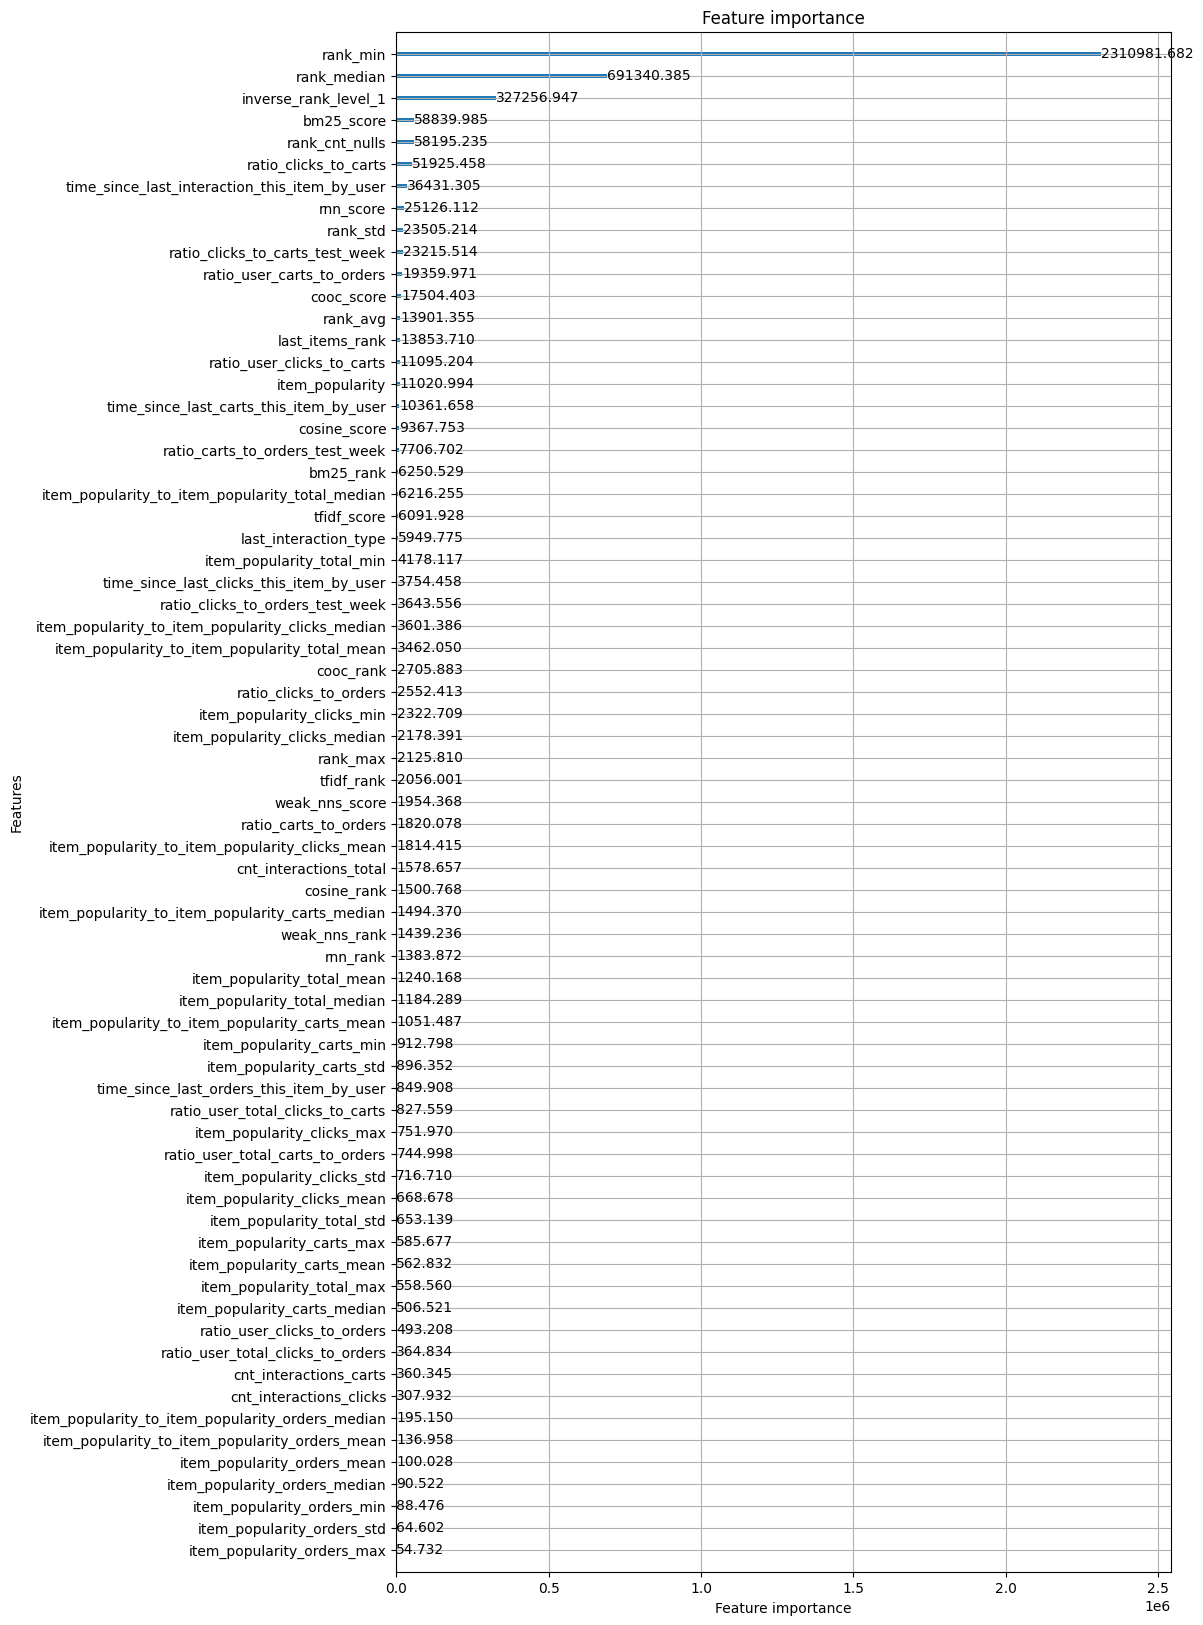

In [5]:
lgb.plot_importance(bst, importance_type="gain", figsize=(10, 20))

In [35]:
df_merged = pl.read_parquet(
    config.cur_model_output_path + "train_clicks_orders.parquet"
)

In [ ]:
df_merged.shape

In [ ]:
df_merged.filter(pl.col("session") == 13433182).filter(pl.col("item_id") == 1537673)

In [ ]:
df_merged[["session", "item_id"]].groupby(["session", "item_id"]).count().filter(
    pl.col("count") > 1
)

In [ ]:
df_merged[df_merged["session"] == 13405261]

In [ ]:
df_merged

In [ ]:
%%time

columns = [
    col for col in df_merged.columns if "_score" in col or "_rank" in col
]
X_train = df_merged[columns].to_numpy(dtype=np.float32)
df_merged['target'] = (df_merged['target'] > 0) * 1
y_train = df_merged['target'].astype(np.int8)

In [ ]:
%%time

train_groups = utils.get_group_for_lgb(df_merged["session"].values)

In [ ]:
%%time

lgb_train = lgb.Dataset(
    X_train,
    y_train,
    feature_name=columns,
    group=train_groups,
    free_raw_data=False,
)

In [ ]:
%%time

lgb_train.construct()

In [ ]:
lgb_train.get_label()

In [ ]:
lgb_train.get_feature_name()

In [ ]:
len(lgb_train.get_data())

In [ ]:
%%time

len(np.where((np.isnan(lgb_train.get_data()).all(axis=1) == False) & (lgb_train.get_label() == 1))[0])

In [ ]:
df_merged.loc[
    np.where(
        (np.isnan(lgb_train.get_data()).all(axis=1) == False)
        & (lgb_train.get_label() == 1)
    )[0]
]

In [ ]:
946438 / len(df_merged[df_merged["target"] == 1])

In [ ]:
df_merged.loc[
    np.where(
        (np.isnan(lgb_train.get_data()).all(axis=1) == True)
        & (lgb_train.get_label() == 0)
    )[0]
]